In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import json
import seaborn

In [5]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

# First try

## Build Data

In [4]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [5]:
# Infinite Horizon Welfare
directory = 'run_data/two_wells_analysis/infinite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        #print(param_data['controller']['time_horizon'])
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    data['infinite welfare'][well_distance] = result_data['inputs']

In [6]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

In [7]:
# RHG
directory = 'run_data/two_wells_analysis/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [8]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [9]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

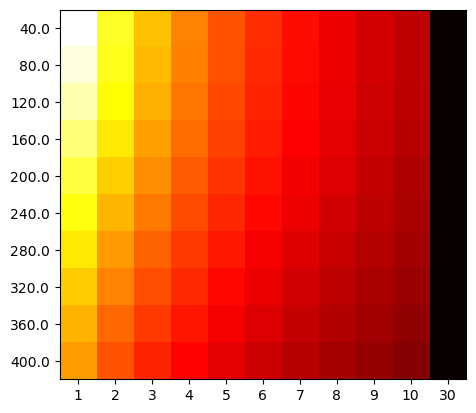

In [10]:
fig, ax = plt.subplots(1,1)
ax.imshow(finite_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

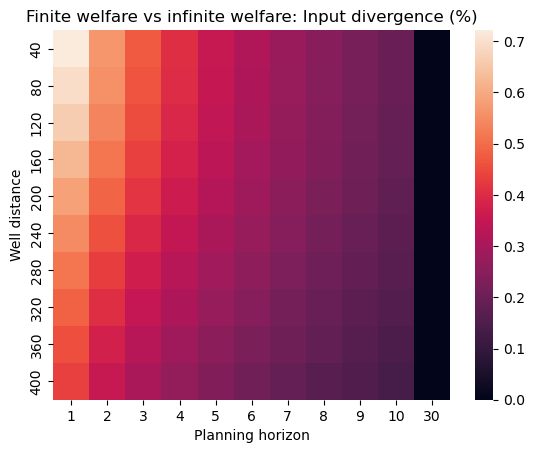

In [25]:
seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [31]:
finite_infinite_divergence[0][0]*100

np.float64(0.721583205764773)

In [27]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

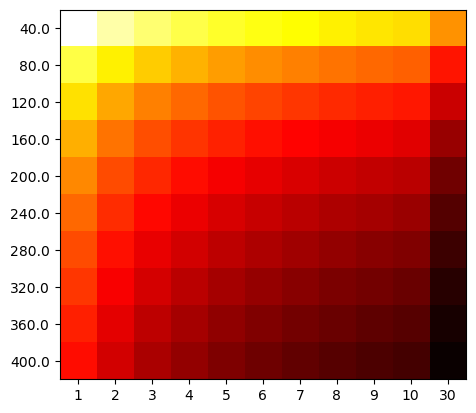

In [33]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

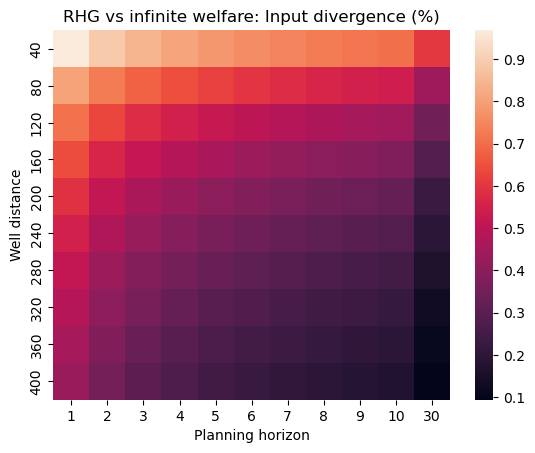

In [28]:
seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [34]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(0.9688086149467177), np.float64(0.09418218254953342))

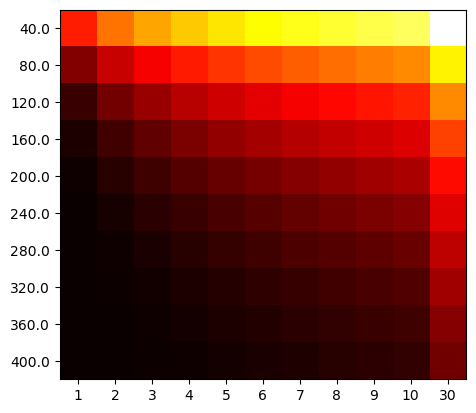

In [35]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_finite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

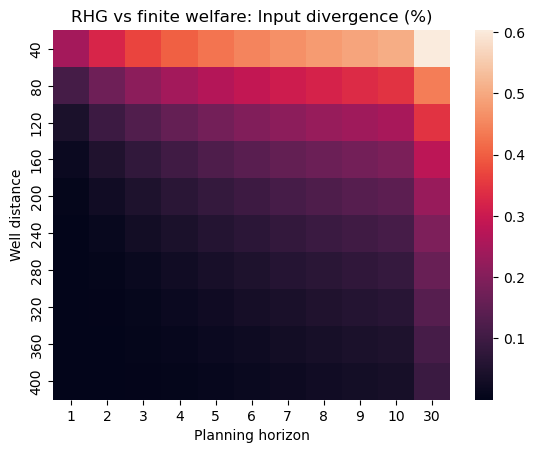

In [30]:
seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [36]:
RHG_finite_divergence.max()*100, RHG_finite_divergence.min()*100

(np.float64(0.6034687381394516), np.float64(2.802389591835921e-06))

In [37]:
RHG_infinite_divergence[0][10]

np.float64(0.006034687381394515)

Divergence between close and far wells

In [38]:
input_distances = np.linalg.norm(
    data['RHG'][400][30] - data['RHG'][40][30],
    axis=0)
input_divergences = input_distances / np.linalg.norm(
    data['RHG'][400][30], axis=0)
input_divergences.sum()/input_divergences.shape[0]

np.float64(0.005298572475028753)

# Smaller conductivity and new quadratic cost

## Build Data

In [5]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [6]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_low_k_c/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_redefinition_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for well_distance in data['finite welfare'].keys():
    data['infinite welfare'][well_distance] = data['finite welfare'][well_distance][30]

In [7]:
# RHG
directory = 'run_data/two_wells_analysis_low_k_c/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_redefinition_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [8]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [9]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

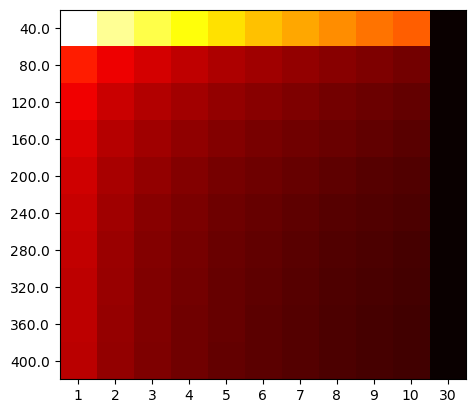

In [10]:
fig, ax = plt.subplots(1,1)
ax.imshow(finite_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [19]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(1.3016056163788996), np.float64(0.5316697637680221))

In [12]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

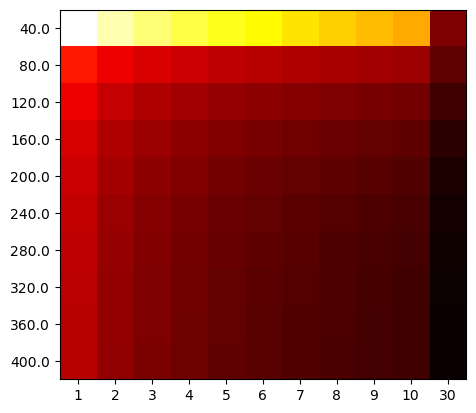

In [13]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [14]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(1.3242035146631466), np.float64(0.00207879885499906))

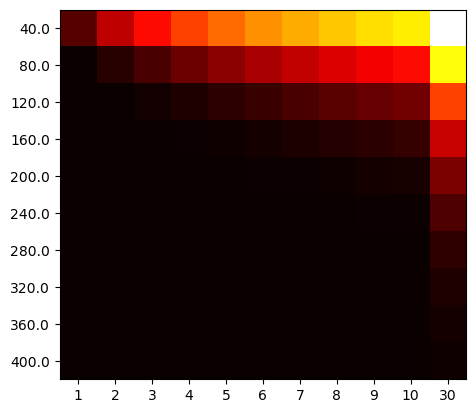

In [15]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_finite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [16]:
RHG_finite_divergence.max()*100, RHG_finite_divergence.min()*100

(np.float64(0.230276582569527), np.float64(0.0))

In [17]:
RHG_infinite_divergence[0][10]

np.float64(0.00230276582569527)

Divergence between close and far wells

In [18]:
input_distances = np.linalg.norm(
    data['RHG'][400][30] - data['RHG'][40][30],
    axis=0)
input_divergences = input_distances / np.linalg.norm(
    data['RHG'][400][30], axis=0)
input_divergences.sum()/input_divergences.shape[0]

np.float64(0.01581628922277281)

# Dimensionless system

## Build Data

In [2]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [6]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis_dimless/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

# Infinite Horizon Welfare
for well_distance in data['finite welfare'].keys():
    data['infinite welfare'][well_distance] = data['finite welfare'][well_distance][30]

In [7]:
# RHG
directory = 'run_data/two_wells_analysis_dimless/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_dimensionless_parameters_changed_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

## Display data

In [8]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [9]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

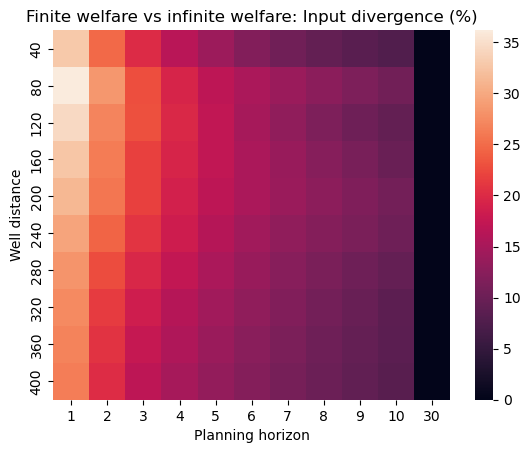

In [19]:
seaborn.heatmap(finite_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("Finite welfare vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [11]:
finite_infinite_divergence[0][0]*100, finite_infinite_divergence[1][0]*100

(np.float64(32.841196820056425), np.float64(36.19327444608803))

In [12]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

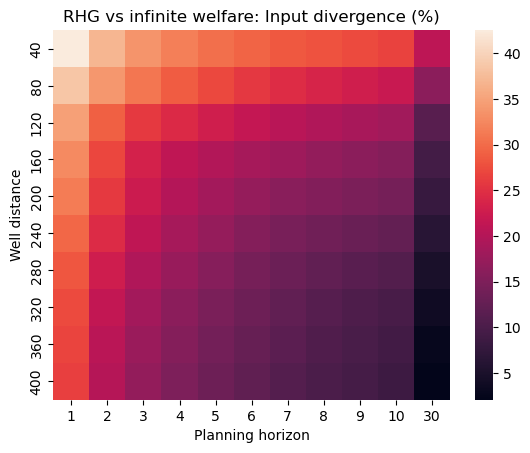

In [20]:
seaborn.heatmap(RHG_infinite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs infinite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [14]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(42.52772699810686), np.float64(2.0878663519057308))

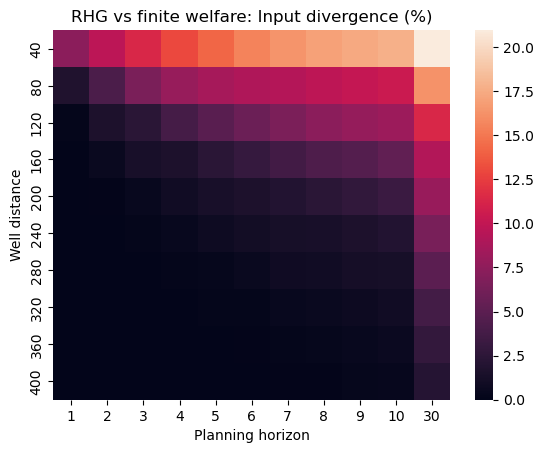

In [21]:
seaborn.heatmap(RHG_finite_divergence*100,
                xticklabels=horizons, yticklabels=distances.astype(int))

plt.title("RHG vs finite welfare: Input divergence (%)")
plt.xlabel("Planning horizon")
plt.ylabel("Well distance")

plt.show()

In [16]:
RHG_finite_divergence.max()*100, RHG_finite_divergence.min()*100

(np.float64(20.956305327377336), np.float64(0.0))

In [17]:
RHG_infinite_divergence[0][10]

np.float64(0.20956305327377336)

Divergence between close and far wells

In [18]:
input_distances = np.linalg.norm(
    data['RHG'][400][30] - data['RHG'][40][30],
    axis=0)
input_divergences = input_distances / np.linalg.norm(
    data['RHG'][400][30], axis=0)
input_divergences.sum()/input_divergences.shape[0]

np.float64(0.1707265614397406)